# F1 Regulation Change Analysis: Driver and Car Fixed Effects

Two-way fixed-effects (AKM-style) decomposition of qualifying pace into driver,
car (team-season) and qualifying-segment effects, 2018-2026, with the 2022 and
2026 regulation changes as the reported transitions.

**Method**

- The outcome is each driver's best qualifying lap in a session, as a percentage
  above that session's pole time. Effects are therefore relative to the field, in
  percentage points of pole time.
- Driver and car effects are identified from drivers who change teams. Section 5
  checks that all team-seasons form one connected network.
- Standard errors are clustered by session (circuit-season) and reported for every
  driver effect, car effect and regulation delta. Each regulation delta also gets a
  wild cluster bootstrap p-value (section 6c.1), because 38 session clusters is few
  for cluster-robust standard errors.
- Teams are linked across renames (Sauber, Alfa Romeo Racing, Alfa Romeo, Kick
  Sauber, Audi) so that each gets a delta at both regulation changes.

**Sample rules**

- A session is dropped if any driver's best lap was set on intermediate or wet tyres.
- A session is dropped if its median Q3-vs-Q2 time (same drivers, at least five
  pairs) is more than 2% slower. This catches sessions such as Hungary 2018 and
  Spa 2018, where Q2 and Q3 were wet, the front-runners' only dry laps were Q1 laps
  set without pushing, and the session's "pole" was a Q1 time.
- Laps more than 8% off pole are trimmed. After the session rules this removes no
  observation: nothing in the data lies between 6.5% and 18.4% off pole, so any trim
  from 7% to 18% gives the same sample. A 5% trim would remove genuine slow laps,
  including eight Aston Martin 2026 laps at 5.4-6.4% off pole.
- Set `DRY_Q3_RULE = False` in the cell below the wet-tyre filter and
  `OUTLIER_PCT = 1e9` to see the unfiltered data.

**Contents**

Section 7 contains the robustness checks: identification support per team-season,
outlier-trim and pooling-threshold sensitivity, leave-one-circuit-out, variance
decomposition, a mover-residual check of the exogenous-mobility assumption, and
held-out-circuit prediction. Section 8 writes the seven figures to `figures/` as
PDF and 300 dpi PNG.

**Data.** Raw timing data is not included in this repository. The first run
downloads it through FastF1 and caches it locally in `data/` and `ff1_cache/`.


In [ ]:
!pip install fastf1 linearmodels networkx --quiet --upgrade

In [2]:
import os
import warnings

import fastf1
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

CACHE_DIR = 'ff1_cache'
DATA_DIR = 'data'
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)
fastf1.Cache.enable_cache(CACHE_DIR)

print("fastf1", fastf1.__version__)

import statsmodels.api as sm
from matplotlib.lines import Line2D

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

# One figure style for the paper: recessive axes, light grid, text in ink
# colours rather than series colours. Two categorical colours carry identity
# (before / after a regulation change); grey marks "not distinguishable from zero".
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e1'
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#9a9893'
plt.rcParams.update({
    'font.size': 8.5, 'axes.titlesize': 9.5, 'axes.labelsize': 8.5,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'figure.dpi': 110, 'savefig.dpi': 300,
    'lines.linewidth': 1.4,
})


def save(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(f"{FIG_DIR}/{name}.{ext}", bbox_inches='tight')
    print(f"saved {FIG_DIR}/{name}.pdf and .png")

fastf1 3.9.0


## Section 1 — Circuit Configuration

`fastf1.get_event()` resolves a season + query string using **fuzzy
matching**, which can silently return the wrong event. Two real examples
found while building this:

- `'Spa'` resolves to the **Spanish** Grand Prix (Madrid) in 2026, not
  Spa-Francorchamps — it matches "España" more strongly than "Spa".
- `'Silverstone'` in 2020 resolves to the **70th Anniversary Grand Prix**,
  not the British Grand Prix. Both ran at Silverstone that year as a
  COVID-rescheduled double-header, so the query is genuinely ambiguous.

A wrong match does not raise an error — it returns a valid session for the
wrong circuit, which would silently corrupt the panel. So each circuit
declares an **`expected_location`**, and every resolution is validated
against it before any data is pulled. Per-season `overrides` accept either
a different query string or an integer round number, which is unambiguous.

In [3]:
CIRCUITS = {
    'Austria': {
        'query': 'Austria',
        'expected_location': 'Spielberg',
        'seasons': [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
    },
    'Hungary': {
        'query': 'Hungary',
        'expected_location': 'Budapest',
        'seasons': [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
    },
    'Silverstone': {
        'query': 'Silverstone',
        'expected_location': 'Silverstone',
        'seasons': [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
        # 2020 ran two races here; round 4 is the British GP proper.
        'overrides': {2020: 4},
    },
    'Spa': {
        'query': 'Belgium',
        'expected_location': 'Spa-Francorchamps',
        'seasons': [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
    },
    'Barcelona_pre2023': {
        'query': 'Barcelona',
        'expected_location': 'Barcelona',
        'seasons': [2018, 2019, 2020, 2021, 2022],
    },
    'Barcelona_post2023': {
        'query': 'Barcelona',
        'expected_location': 'Barcelona',
        'seasons': [2023, 2024, 2025, 2026],
    },
}

def get_query(cfg, season):
    """Resolve the lookup key for a circuit-season, honouring overrides."""
    return cfg.get('overrides', {}).get(season, cfg['query'])

TARGETS = [(cid, s) for cid, cfg in CIRCUITS.items() for s in cfg['seasons']]
print(f"{len(CIRCUITS)} circuit identities, {len(TARGETS)} circuit-seasons")

6 circuit identities, 45 circuit-seasons


## Section 2 — Resolution Audit

This resolves every circuit-season to a concrete event and checks the
location against `expected_location` **without downloading any session
data**. It is fast, and it is the gate: if anything fails here, fix the
config before pulling. Pulling first and checking later means silently
building the panel on the wrong races.

In [ ]:
audit_rows = []
for circuit_id, cfg in CIRCUITS.items():
    for season in cfg['seasons']:
        query = get_query(cfg, season)
        try:
            ev = fastf1.get_event(season, query)
            loc = ev['Location']
            ok = cfg['expected_location'].lower() in str(loc).lower()
            audit_rows.append({
                'CircuitID': circuit_id, 'Season': season, 'Query': query,
                'ResolvedEvent': ev['EventName'], 'Location': loc,
                'Round': ev['RoundNumber'], 'Format': ev['EventFormat'],
                'OK': ok,
            })
        except Exception as e:
            audit_rows.append({
                'CircuitID': circuit_id, 'Season': season, 'Query': query,
                'ResolvedEvent': f'ERROR: {type(e).__name__}', 'Location': None,
                'Round': None, 'Format': None, 'OK': False,
            })

audit = pd.DataFrame(audit_rows)
print(audit.to_string(index=False))

bad = audit[~audit['OK']]
print()
if len(bad):
    print(f"*** {len(bad)} FAILED VALIDATION — fix config before pulling ***")
    print(bad[['CircuitID', 'Season', 'Query', 'ResolvedEvent', 'Location']].to_string(index=False))
else:
    print("All circuit-seasons resolved to the expected location.")

## Section 3 — Data Pull

For each validated circuit-season, this loads the **knockout qualifying**
session. `event.get_qualifying()` always returns the single-lap knockout
session, including on sprint weekends — in 2021–22 the *Saturday race* was
briefly branded "Sprint Qualifying", but that is a race, not this session,
and fastf1 resolves the naming internally.

Lap times are stored as **floats in seconds** (`LapTimeSeconds`) rather
than as pandas timedeltas, because timedeltas do not survive a CSV
round-trip cleanly and these files are written to disk as checkpoints.

All laps are kept at this stage — filtering happens in Section 4, so the
filtering decisions are visible and auditable rather than buried in the
download step. Set `FORCE_REFRESH = True` to re-pull a circuit-season that
is already cached.

In [5]:
FORCE_REFRESH = False

WEATHER_COLS = ['AirTemp', 'TrackTemp', 'Humidity', 'Pressure',
                'WindSpeed', 'WindDirection', 'Rainfall']

KEEP_LAP_COLS = ['Driver', 'DriverNumber', 'Team', 'LapNumber', 'Stint',
                 'Compound', 'TyreLife', 'TrackStatus', 'IsAccurate', 'Deleted']

def pull_qualifying(circuit_id, query, season):
    """Return a tidy DataFrame of all qualifying laps for one circuit-season."""
    event = fastf1.get_event(season, query)
    session = event.get_qualifying()
    session.load()

    laps = session.laps.copy()
    if laps.empty:
        raise ValueError("session returned zero laps")

    laps['LapTimeSeconds'] = laps['LapTime'].dt.total_seconds()

    cols = [c for c in KEEP_LAP_COLS if c in laps.columns]
    out = laps[cols + ['LapTimeSeconds', 'Time']].copy()

    weather = session.weather_data
    if weather is not None and not weather.empty:
        wcols = ['Time'] + [c for c in WEATHER_COLS if c in weather.columns]
        out = pd.merge_asof(
            out.sort_values('Time'),
            weather[wcols].sort_values('Time'),
            on='Time', direction='nearest',
        )
    else:
        for c in WEATHER_COLS:
            out[c] = np.nan

    out = out.drop(columns=['Time'])
    out['CircuitID'] = circuit_id
    out['Season'] = season
    out['RoundNumber'] = event['RoundNumber']
    out['EventName'] = event['EventName']
    out['EventFormat'] = event['EventFormat']
    out['IsSprintWeekend'] = event['EventFormat'] != 'conventional'
    return out


frames = []
for circuit_id, cfg in CIRCUITS.items():
    for season in cfg['seasons']:
        path = f"{DATA_DIR}/{circuit_id}_{season}.csv"

        if os.path.exists(path) and not FORCE_REFRESH:
            frames.append(pd.read_csv(path))
            print(f"[cached] {circuit_id} {season}")
            continue

        query = get_query(cfg, season)
        try:
            df = pull_qualifying(circuit_id, query, season)
            df.to_csv(path, index=False)
            frames.append(df)
            print(f"[ok]     {circuit_id} {season}: {len(df)} laps "
                  f"({df['EventName'].iloc[0]}, round {df['RoundNumber'].iloc[0]})")
        except Exception as e:
            print(f"[FAIL]   {circuit_id} {season}: {type(e).__name__}: {e}")

raw_panel = pd.concat(frames, ignore_index=True)
print(f"\nraw_panel: {len(raw_panel)} laps across {len(frames)} circuit-seasons")

[cached] Austria 2018
[cached] Austria 2019
[cached] Austria 2020
[cached] Austria 2021
[cached] Austria 2022
[cached] Austria 2023
[cached] Austria 2024
[cached] Austria 2025
[cached] Austria 2026
[cached] Hungary 2018
[cached] Hungary 2019
[cached] Hungary 2020
[cached] Hungary 2021
[cached] Hungary 2022
[cached] Hungary 2023
[cached] Hungary 2024
[cached] Hungary 2025
[cached] Hungary 2026
[cached] Silverstone 2018
[cached] Silverstone 2019
[cached] Silverstone 2020
[cached] Silverstone 2021
[cached] Silverstone 2022
[cached] Silverstone 2023
[cached] Silverstone 2024
[cached] Silverstone 2025
[cached] Silverstone 2026
[cached] Spa 2018
[cached] Spa 2019
[cached] Spa 2020
[cached] Spa 2021
[cached] Spa 2022
[cached] Spa 2023
[cached] Spa 2024
[cached] Spa 2025
[cached] Spa 2026
[cached] Barcelona_pre2023 2018
[cached] Barcelona_pre2023 2019
[cached] Barcelona_pre2023 2020
[cached] Barcelona_pre2023 2021
[cached] Barcelona_pre2023 2022
[cached] Barcelona_post2023 2023
[cached] Barcel

In [6]:
loaded = set(map(tuple, raw_panel[['CircuitID', 'Season']].drop_duplicates().values))
missing = [t for t in TARGETS if t not in loaded]

print(f"Loaded {len(loaded)} / {len(TARGETS)} circuit-seasons")
if missing:
    print("MISSING:", missing)
else:
    print("No gaps.")

# Confirm what actually landed on disk matches what was intended.
print()
provenance = (raw_panel
              .groupby(['CircuitID', 'Season'])
              .agg(EventName=('EventName', 'first'),
                   Round=('RoundNumber', 'first'),
                   Sprint=('IsSprintWeekend', 'first'),
                   Laps=('LapTimeSeconds', 'size'),
                   Drivers=('Driver', 'nunique'))
              .reset_index())
print(provenance.to_string(index=False))

Loaded 45 / 45 circuit-seasons
No gaps.

         CircuitID  Season            EventName  Round  Sprint  Laps  Drivers
           Austria    2018  Austrian Grand Prix      9   False   331       20
           Austria    2019  Austrian Grand Prix      9   False   314       20
           Austria    2020  Austrian Grand Prix      1   False   298       20
           Austria    2021  Austrian Grand Prix      9   False   299       20
           Austria    2022  Austrian Grand Prix     11    True   368       20
           Austria    2023  Austrian Grand Prix      9    True   377       20
           Austria    2024  Austrian Grand Prix     11    True   320       20
           Austria    2025  Austrian Grand Prix     11   False   310       20
           Austria    2026  Austrian Grand Prix      8   False   289       22
Barcelona_post2023    2023   Spanish Grand Prix      7   False   337       20
Barcelona_post2023    2024   Spanish Grand Prix     10   False   257       20
Barcelona_post2023    2

## Section 3b — Qualifying Segment Times

Qualifying runs in three segments and the track rubbers in throughout. Measured
on this panel, the same driver's Q3 lap is a median **0.91%** of a lap quicker
than their own Q1 lap (IQR 0.47–1.38%) — roughly eight tenths at Silverstone.

That matters because a driver knocked out in Q1 sets their best lap on a green
track while a driver who reaches Q3 sets theirs half an hour later on a fully
rubbered one. Comparing those two as if conditions were equal charges the Q1
driver for track evolution and books it as lack of pace. Since the drivers who
exit early cluster in the slower teams, the bias is systematic, not noise.

`session.results` carries each driver's official best time in each segment as
separate `Q1`, `Q2` and `Q3` columns. Those are pulled here so every lap can be
labelled with the segment it was set in, and the evolution absorbed by a fixed
effect in Section 6 rather than left in the driver term.

In [7]:
SEG_PATH = f"{DATA_DIR}/_segment_times.csv"

def pull_segments(circuit_id, query, season):
    event = fastf1.get_event(season, query)
    s = event.get_qualifying()
    s.load(telemetry=False, weather=False, messages=False)
    r = s.results[['Abbreviation', 'Q1', 'Q2', 'Q3']].copy()
    for q in ['Q1', 'Q2', 'Q3']:
        r[q] = r[q].dt.total_seconds()
    r = r.rename(columns={'Abbreviation': 'Driver'})
    r['CircuitID'] = circuit_id
    r['Season'] = season
    return r


if os.path.exists(SEG_PATH) and not FORCE_REFRESH:
    segment_times = pd.read_csv(SEG_PATH)
    print(f"[cached] segment times: {len(segment_times)} driver-sessions")
else:
    seg_frames = []
    for circuit_id, cfg in CIRCUITS.items():
        for season in cfg['seasons']:
            try:
                seg_frames.append(pull_segments(circuit_id, get_query(cfg, season), season))
                print(f"[ok]   {circuit_id} {season}")
            except Exception as e:
                print(f"[FAIL] {circuit_id} {season}: {type(e).__name__}: {e}")
    segment_times = pd.concat(seg_frames, ignore_index=True)
    segment_times.to_csv(SEG_PATH, index=False)
    print(f"\nsegment times: {len(segment_times)} driver-sessions")

deepest = np.where(segment_times['Q3'].notna(), 'Q3',
           np.where(segment_times['Q2'].notna(), 'Q2', 'Q1'))
print("\ndeepest segment reached:")
print(pd.Series(deepest).value_counts().to_string())

[cached] segment times: 910 driver-sessions

deepest segment reached:
Q3    442
Q1    235
Q2    233


## Section 4 — Cleaning & Normalization

In [8]:
SESSION_KEYS = ['CircuitID', 'Season']
WET_TYRES = ['INTERMEDIATE', 'WET']

clean = raw_panel.copy()

# --- 1. laps with no recorded time are unusable ---
n0 = len(clean)
clean = clean[clean['LapTimeSeconds'].notna()]
print(f"dropped {n0 - len(clean):5d} laps with no lap time")

# --- 2. classify session conditions BEFORE any other filtering ---
# Order matters: doing this after the accuracy filter previously let Spa 2021
# through, because the laps carrying the rain signal were the ones removed.
#
# The compound is used rather than the `Rainfall` sensor. `Rainfall` reports
# whether precipitation is falling at that instant, which is False on a soaked
# but drying track (Spa 2021) and True when it rains around a session whose
# timed laps were all on slicks (Hungary 2024: 81% rain samples, zero wet-tyre
# laps). Teams fit inters or wets only when the track is genuinely wet.
#
# A session is excluded if ANY driver's best lap was set on a wet-weather tyre,
# not merely the pole lap. Testing pole alone kept mixed, drying sessions where
# the front of the grid ran late on slicks while drivers eliminated earlier were
# stuck with damp-track times. Silverstone 2024 was such a session: pole on
# softs, 10% of the field on inters, and Magnussen 8.3% off pole -- roughly
# seven seconds, which is not a car or driver effect but a compromised lap.
prov = clean.loc[clean.groupby(SESSION_KEYS + ['Driver'])['LapTimeSeconds'].idxmin()]
wet_any = prov[prov['Compound'].isin(WET_TYRES)].groupby(SESSION_KEYS).size()
wet_sessions = set(wet_any.index)

print("\nsessions excluded (any driver's best lap on a wet tyre):")
if wet_sessions:
    for k in sorted(wet_sessions):
        print(f"  {k}: {int(wet_any[k])} of "
              f"{int((prov.set_index(SESSION_KEYS).index == k).sum())} drivers on wets")
else:
    print("  none")

n1 = len(clean)
clean = clean[~clean.set_index(SESSION_KEYS).index.isin(wet_sessions)]
print(f"\ndropped {n1 - len(clean):5d} laps from mixed or wet sessions")

# --- 2b. sessions whose Q3 was wet ---
# A session is usable only if the segment where front-runners actually push, Q3,
# was dry. Where Q2/Q3 were wet (Hungary 2018, Spa 2018) the front-runners' only
# dry laps are Q1 laps set without pushing, and the session "pole" is a Q1 time.
# The test is the median over drivers with both a Q2 and a Q3 time of
# (Q3 - Q2) / Q2, so one driver's error or missing lap cannot trigger it. In dry
# sessions this sits near -0.3% (track improves); every dry session in the sample
# is within +0.3%, and the wet ones are above +3%.
DRY_Q3_RULE = True
DRY_Q3_MAX_PCT = 2.0
MIN_PAIRS = 5
pairs = segment_times.dropna(subset=['Q2', 'Q3']).copy()
pairs['q3_vs_q2'] = 100 * (pairs['Q3'] - pairs['Q2']) / pairs['Q2']
q3chk = (pairs.groupby(SESSION_KEYS)['q3_vs_q2']
              .agg(median='median', pairs='count').reset_index())
wet_q3 = {(r.CircuitID, r.Season) for r in q3chk.itertuples()
          if r.median > DRY_Q3_MAX_PCT and r.pairs >= MIN_PAIRS}
print("\nQ3 vs Q2 by session (median % over drivers with both times), worst 6:")
print(q3chk.sort_values('median', ascending=False).head(6).round(2).to_string(index=False))
if DRY_Q3_RULE:
    print("\nsessions excluded (Q3 median more than "
          f"{DRY_Q3_MAX_PCT}% slower than Q2): {sorted(wet_q3)}")
    n1b = len(clean)
    clean = clean[~clean.set_index(SESSION_KEYS).index.isin(wet_q3)]
    print(f"dropped {n1b - len(clean):5d} laps from sessions with a wet Q3")

# --- 3. lap-level quality filters ---
n2 = len(clean)
if 'Deleted' in clean.columns:
    clean = clean[clean['Deleted'] != True]
print(f"dropped {n2 - len(clean):5d} deleted laps (track limits)")

n3 = len(clean)
if 'IsAccurate' in clean.columns:
    clean = clean[clean['IsAccurate'] == True]
print(f"dropped {n3 - len(clean):5d} laps not marked accurate (out/in laps, flags, timing errors)")

print(f"\nremaining: {len(clean)} laps across {clean.groupby(SESSION_KEYS).ngroups} circuit-seasons")

dropped  4558 laps with no lap time

sessions excluded (any driver's best lap on a wet tyre):
  ('Silverstone', 2022): 20 of 20 drivers on wets
  ('Silverstone', 2024): 2 of 20 drivers on wets
  ('Spa', 2021): 20 of 20 drivers on wets
  ('Spa', 2023): 6 of 20 drivers on wets
  ('Spa', 2024): 20 of 20 drivers on wets

dropped  1286 laps from mixed or wet sessions

Q3 vs Q2 by session (median % over drivers with both times), worst 6:
  CircuitID  Season  median  pairs
        Spa    2018   18.52      9
    Hungary    2018    6.74     10
        Spa    2021    3.53      9
    Hungary    2025    0.28     10
Silverstone    2022    0.17     10
        Spa    2025    0.01     10

sessions excluded (Q3 median more than 2.0% slower than Q2): [('Hungary', 2018), ('Spa', 2018), ('Spa', 2021)]
dropped   488 laps from sessions with a wet Q3
dropped   126 deleted laps (track limits)
dropped  3108 laps not marked accurate (out/in laps, flags, timing errors)

remaining: 4115 laps across 38 circuit-sea

In [9]:
OUTLIER_PCT = 8.0

best = clean.loc[clean.groupby(SESSION_KEYS + ['Driver'])['LapTimeSeconds'].idxmin()].copy()
best = best.reset_index(drop=True)

# --- label each best lap with the segment it was actually set in ---
# Note this is the segment of the driver's best lap, not the deepest segment
# reached: a driver who botches their Q3 run keeps their Q2 time, and it is the
# track condition when the lap was set that matters here.
best = best.merge(segment_times, on=['CircuitID', 'Season', 'Driver'], how='left')

def assign_segment(row):
    avail = {q: row[q] for q in ('Q1', 'Q2', 'Q3') if pd.notna(row[q])}
    if not avail:
        return 'UNKNOWN', np.nan
    seg = min(avail, key=lambda q: abs(avail[q] - row['LapTimeSeconds']))
    return seg, abs(avail[seg] - row['LapTimeSeconds'])

lab = best.apply(assign_segment, axis=1, result_type='expand')
best['BestSegment'] = lab[0]
best['SegmentMatchErr'] = lab[1]

print(f"segment assigned within 0.05s for "
      f"{int((best['SegmentMatchErr'] < 0.05).sum())}/{len(best)} rows")
print(best['BestSegment'].value_counts().to_string())

unplaced = best['BestSegment'].eq('UNKNOWN') | best['SegmentMatchErr'].ge(0.05)
if unplaced.any():
    print(f"\ndropping {int(unplaced.sum())} rows with no reliable segment match")
    best = best[~unplaced].reset_index(drop=True)

best['PoleTime'] = best.groupby(SESSION_KEYS)['LapTimeSeconds'].transform('min')
best['GapToPole'] = best['LapTimeSeconds'] - best['PoleTime']
best['PctOffPole'] = 100 * best['GapToPole'] / best['PoleTime']

# Kept for the trim-threshold sensitivity check in Section 7.
best_pretrim = best.copy()

# --- trim residual outliers ---
# Pole-to-last spread in a clean dry qualifying session runs about 3-4% of a
# lap. Anything beyond 8% is an aborted lap, a lap ruined by traffic or a yellow,
# or a damp window that survived the session-level filter. Least squares weights
# these hardest, so a single such lap can move a driver effect by whole
# percentage points and force the car effect the other way to compensate.
bad = best['PctOffPole'] > OUTLIER_PCT
if bad.any():
    print(f"\ndropping {int(bad.sum())} driver-sessions over {OUTLIER_PCT}% off pole:")
    print(best.loc[bad, SESSION_KEYS + ['Driver', 'Team', 'BestSegment', 'PctOffPole']]
              .sort_values('PctOffPole', ascending=False).round(2).to_string(index=False))
    best = best[~bad].reset_index(drop=True)
    # pole is unchanged by the trim (it is the fastest lap), so gaps stand

print(f"\n{len(best)} driver-session rows across "
      f"{best.groupby(SESSION_KEYS).ngroups} circuit-seasons")

assert (best['GapToPole'] >= -1e-6).all(), "negative gap -- pole logic wrong"
assert best.groupby(SESSION_KEYS + ['Driver']).size().max() == 1, "duplicate driver-session rows"
print("sanity checks passed")

segment assigned within 0.05s for 760/761 rows
BestSegment
Q3    283
Q1    248
Q2    230

dropping 1 rows with no reliable segment match

760 driver-session rows across 38 circuit-seasons
sanity checks passed


## Section 5 — Connectivity Analysis

The two-way fixed effects model separates driver skill from car performance
using drivers as the link between cars. The unit for "car" is the
**team-season** (a 2021 Red Bull and a 2022 Red Bull are different cars),
and two team-seasons are connected when the same driver appears in both.

Two kinds of edge both matter:

- **Across teams** — Bottas at Mercedes 2021 and Alfa Romeo 2022 links
  those two cars.
- **Across seasons at one team** — Verstappen at Red Bull 2021 and 2022
  links those two cars, and that link is what identifies the regulation
  effect itself.

Only team-seasons inside the **largest connected component** have car
effects estimable on a common scale. An isolated group is internally
consistent but floats on its own scale, so its numbers cannot be compared
against the rest of the grid. Those are reported by name and excluded from
the regression rather than dropped silently.

Connectivity is computed **separately per window**, because the two
regulation shocks are estimated as two independent models.

In [10]:
ALL_SEASONS = [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

# The two transitions the paper reports on. 2023 is NOT a reported year -- it is
# the bridge that connects the pre-2022 era to the post-2024 era, so that both
# shocks land on one common scale instead of two incomparable ones.
SHOCKS = {'2022_shock': (2021, 2022), '2026_shock': (2025, 2026)}


def build_car_graph(panel):
    G = nx.Graph()
    for cs in panel[['Season', 'Team']].drop_duplicates().itertuples(index=False):
        G.add_node((cs.Season, cs.Team))
    for driver, g in panel.groupby('Driver'):
        nodes = sorted(set(zip(g['Season'], g['Team'])))
        for i in range(len(nodes)):
            for j in range(i + 1, len(nodes)):
                if G.has_edge(nodes[i], nodes[j]):
                    G[nodes[i]][nodes[j]]['via'].append(driver)
                else:
                    G.add_edge(nodes[i], nodes[j], via=[driver])
    return G


# ONE graph over every season. The extra years exist to identify driver skill;
# they are not filtered out before estimation.
G = build_car_graph(best)
comps = sorted(nx.connected_components(G), key=len, reverse=True)
main_component = comps[0] if comps else set()

print(f"{len(best)} driver-session rows | {G.number_of_nodes()} team-seasons "
      f"| {len(comps)} component(s), sizes={[len(c) for c in comps]}")
for c in comps[1:]:
    print(f"    isolated (excluded): {sorted(c)}")

best['InMainComponent'] = [(r.Season, r.Team) in main_component
                           for r in best.itertuples(index=False)]
kept = int(best['InMainComponent'].sum())
print(f"\nestimable rows: {kept}/{len(best)}   ({len(best) - kept} excluded)")

print("\ncoverage of the reported years within the main component:")
rep = best[best['InMainComponent'] & best['Season'].isin(
    [2020, 2021, 2022, 2024, 2025, 2026])]
print(rep.groupby('Season').agg(rows=('Driver', 'size'),
                                teams=('Team', 'nunique'),
                                drivers=('Driver', 'nunique')).to_string())


760 driver-session rows | 91 team-seasons | 1 component(s), sizes=[91]

estimable rows: 760/760   (0 excluded)

coverage of the reported years within the main component:
        rows  teams  drivers
Season                      
2020     100     10       21
2021      79     10       20
2022      79     10       20
2024      60     10       20
2025     100     10       20
2026     110     11       22


The edges that carry identification are listed below. Moves between teams
are the strongest links, since they place two different cars under the same
driver in overlapping conditions.

In [11]:
print("driver moves between teams (the edges that identify driver skill):\n")
moves = []
for a, b, data in G.edges(data=True):
    if a[1] != b[1]:
        for d in data['via']:
            moves.append((d, min(a[0], b[0]), f"{a[1]} {a[0]}", f"{b[1]} {b[0]}"))
for d, _, frm, to in sorted(moves, key=lambda m: (m[0], m[1])):
    print(f"  {d}: {frm}  <->  {to}")
print(f"\n{len(moves)} switch edges, {len(set(m[0] for m in moves))} distinct drivers")


driver moves between teams (the edges that identify driver skill):

  ALB: Toro Rosso 2019  <->  Red Bull Racing 2019
  ALB: Toro Rosso 2019  <->  Red Bull Racing 2020
  ALB: Toro Rosso 2019  <->  Williams 2022
  ALB: Toro Rosso 2019  <->  Williams 2023
  ALB: Toro Rosso 2019  <->  Williams 2024
  ALB: Toro Rosso 2019  <->  Williams 2025
  ALB: Toro Rosso 2019  <->  Williams 2026
  ALB: Red Bull Racing 2019  <->  Williams 2022
  ALB: Red Bull Racing 2019  <->  Williams 2023
  ALB: Red Bull Racing 2019  <->  Williams 2024
  ALB: Red Bull Racing 2019  <->  Williams 2025
  ALB: Red Bull Racing 2019  <->  Williams 2026
  ALB: Red Bull Racing 2020  <->  Williams 2022
  ALB: Red Bull Racing 2020  <->  Williams 2023
  ALB: Red Bull Racing 2020  <->  Williams 2024
  ALB: Red Bull Racing 2020  <->  Williams 2025
  ALB: Red Bull Racing 2020  <->  Williams 2026
  ALO: McLaren 2018  <->  Alpine 2021
  ALO: McLaren 2018  <->  Alpine 2022
  ALO: McLaren 2018  <->  Aston Martin 2023
  ALO: McLaren 20

In [12]:
for name, (pre, post) in SHOCKS.items():
    sub = best[best['InMainComponent'] & best['Season'].isin([pre, post])]
    print(f"{name} ({pre} vs {post}): {len(sub)} rows | "
          f"{sub['Team'].nunique()} teams | {sub['Driver'].nunique()} drivers | "
          f"{sub.groupby(SESSION_KEYS).ngroups} circuit-seasons")
    for s in (pre, post):
        t = sorted(sub[sub['Season'] == s]['Team'].unique())
        print(f"    {s}: {len(t)} teams -> {t}")
    print()


2022_shock (2021 vs 2022): 158 rows | 11 teams | 23 drivers | 8 circuit-seasons
    2021: 10 teams -> ['Alfa Romeo Racing', 'AlphaTauri', 'Alpine', 'Aston Martin', 'Ferrari', 'Haas F1 Team', 'McLaren', 'Mercedes', 'Red Bull Racing', 'Williams']
    2022: 10 teams -> ['Alfa Romeo', 'AlphaTauri', 'Alpine', 'Aston Martin', 'Ferrari', 'Haas F1 Team', 'McLaren', 'Mercedes', 'Red Bull Racing', 'Williams']

2026_shock (2025 vs 2026): 210 rows | 12 teams | 23 drivers | 10 circuit-seasons
    2025: 10 teams -> ['Alpine', 'Aston Martin', 'Ferrari', 'Haas F1 Team', 'Kick Sauber', 'McLaren', 'Mercedes', 'Racing Bulls', 'Red Bull Racing', 'Williams']
    2026: 11 teams -> ['Alpine', 'Aston Martin', 'Audi', 'Cadillac', 'Ferrari', 'Haas F1 Team', 'McLaren', 'Mercedes', 'Racing Bulls', 'Red Bull Racing', 'Williams']



In [13]:
# Which teams/drivers are estimable in the reported years
rep = best[best['InMainComponent'] & best['Season'].isin([2020, 2021, 2022, 2024, 2025, 2026])]
print("teams on the common scale, by reported season:\n")
print(rep.groupby(['Season', 'Team'])['Driver']
         .apply(lambda s: sorted(s.unique())).to_string())


teams on the common scale, by reported season:

Season  Team             
2020    Alfa Romeo Racing         [GIO, RAI]
        AlphaTauri                [GAS, KVY]
        Ferrari                   [LEC, VET]
        Haas F1 Team              [GRO, MAG]
        McLaren                   [NOR, SAI]
        Mercedes                  [BOT, HAM]
        Racing Point         [HUL, PER, STR]
        Red Bull Racing           [ALB, VER]
        Renault                   [OCO, RIC]
        Williams                  [LAT, RUS]
2021    Alfa Romeo Racing         [GIO, RAI]
        AlphaTauri                [GAS, TSU]
        Alpine                    [ALO, OCO]
        Aston Martin              [STR, VET]
        Ferrari                   [LEC, SAI]
        Haas F1 Team              [MAZ, MSC]
        McLaren                   [NOR, RIC]
        Mercedes                  [BOT, HAM]
        Red Bull Racing           [PER, VER]
        Williams                  [LAT, RUS]
2022    Alfa Romeo        

## Section 6 — Two-Way Fixed Effects Model

Qualifying pace is modelled as

    PctOffPole = driver effect + car effect + segment effect + error

where `car` is the team-season. The **segment effect** absorbs track evolution:
it estimates how much of a lap set in Q1 or Q2 is slower purely because the
track was less rubbered, so that deficit is no longer charged to the driver.
Without it, drivers who exit in Q1 — who cluster in the slower teams — absorb
the evolution as apparent lack of skill, and the car effect swings the other
way to compensate.

The full 2018–2026 panel is used for estimation so driver effects are pinned
down by as many team switches as possible; only the transition years are
reported.

`PctOffPole` is measured against each session's own pole lap, so a change
affecting every car equally is invisible here. What is identified is movement
**relative to the field**, not absolute pace. Driver and car effects are
centred on zero and are only jointly identified up to a constant.

The estimation is wrapped in one function, `estimate()`, so that every robustness
check in Section 7 refits exactly the same specification on a different sample.
The cell after it runs the main specification and prints the same summary as
before, now with session-clustered standard errors.

Team names change across seasons without the car programme changing, so the
Sauber lineage is linked for the regulation deltas. Cadillac is a new 2026 entrant
and is not linked to anyone.

In [14]:
MIN_SESSIONS = 5

# Same car programme under different names. Used only to pair team-seasons
# across a regulation change; the model itself estimates one effect per
# team-season regardless of name.
TEAM_ALIAS = {
    'Alfa Romeo Racing': 'Sauber lineage',
    'Alfa Romeo':        'Sauber lineage',
    'Kick Sauber':       'Sauber lineage',
    'Audi':              'Sauber lineage',
    'Sauber':            'Sauber lineage',
}
SHORT = {'Red Bull Racing': 'Red Bull', 'Haas F1 Team': 'Haas',
         'Racing Bulls': 'Racing Bulls', 'RB': 'Racing Bulls',
         'AlphaTauri': 'AlphaTauri', 'Racing Point': 'Racing Point'}


def lineage(team):
    return TEAM_ALIAS.get(team, team)


def estimate(best_df, min_sessions=MIN_SESSIONS, segments=True):
    # Fit the two-way FE model on the largest connected set of best_df.
    # Returns effects centred on their group mean, session-clustered SEs
    # (for centred effects and for regulation deltas), and the fitted objects.
    G_ = build_car_graph(best_df)
    comps_ = sorted(nx.connected_components(G_), key=len, reverse=True)
    main_ = comps_[0]
    md_ = best_df[[(r.Season, r.Team) in main_
                   for r in best_df.itertuples(index=False)]].copy()
    md_['CarUnit'] = md_['Team'] + '_' + md_['Season'].astype(str)
    md_['Session'] = md_['CircuitID'] + '_' + md_['Season'].astype(str)

    counts = md_['Driver'].value_counts()
    rare_ = sorted(counts[counts < min_sessions].index)
    md_['DriverKey'] = md_['Driver'].where(~md_['Driver'].isin(rare_), 'OTHER')

    parts = [pd.get_dummies(md_['DriverKey'], prefix='drv', drop_first=True),
             pd.get_dummies(md_['CarUnit'], prefix='car', drop_first=True)]
    if segments:
        parts.append(pd.get_dummies(md_['BestSegment'], prefix='seg', drop_first=True))
    X_ = sm.add_constant(pd.concat(parts, axis=1).astype(float))
    y_ = md_['PctOffPole'].values
    groups = pd.factorize(md_['Session'])[0]

    fit_ = sm.OLS(y_, X_.values).fit()
    fitc_ = sm.OLS(y_, X_.values).fit(cov_type='cluster',
                                      cov_kwds={'groups': groups})
    cols = list(X_.columns)
    b, V = fitc_.params, fitc_.cov_params()

    def vec(name):
        v = np.zeros(len(cols))
        if name in cols:
            v[cols.index(name)] = 1.0
        return v

    def contrast(w):
        return float(w @ b), float(np.sqrt(w @ V @ w))

    drivers = sorted(md_['DriverKey'].unique())
    units = sorted(md_['CarUnit'].unique())
    dmean = np.mean([vec(f'drv_{d}') for d in drivers], axis=0)
    cmean = np.mean([vec(f'car_{u}') for u in units], axis=0)

    drv_eff, drv_se = {}, {}
    for d in drivers:
        drv_eff[d], drv_se[d] = contrast(vec(f'drv_{d}') - dmean)
    car_eff, car_se = {}, {}
    for u in units:
        car_eff[u], car_se[u] = contrast(vec(f'car_{u}') - cmean)
    seg_eff = {s: (float(b[cols.index(f'seg_{s}')]) if f'seg_{s}' in cols else 0.0)
               for s in sorted(md_['BestSegment'].unique())} if segments else {}

    # regulation deltas, relative to the mean change of teams present on both sides
    unit_of = {(lineage(u.rsplit('_', 1)[0]), int(u.rsplit('_', 1)[1])): u for u in units}
    deltas = {}
    for name, (pre, post) in SHOCKS.items():
        teams = sorted({t for (t, s) in unit_of if s == pre}
                       & {t for (t, s) in unit_of if s == post})
        if not teams:
            continue
        w = {t: vec(f'car_{unit_of[(t, post)]}') - vec(f'car_{unit_of[(t, pre)]}')
             for t in teams}
        wbar = np.mean(list(w.values()), axis=0)
        rows = []
        for t in teams:
            raw, _ = contrast(w[t])
            rel, se_rel = contrast(w[t] - wbar)
            rows.append(dict(Team=t, Pre=car_eff[unit_of[(t, pre)]],
                             Post=car_eff[unit_of[(t, post)]],
                             RawDelta=raw, RelDelta=rel, SE=se_rel, t=rel / se_rel,
                             PreUnit=unit_of[(t, pre)], PostUnit=unit_of[(t, post)]))
        deltas[name] = pd.DataFrame(rows).sort_values('RelDelta').reset_index(drop=True)

    return dict(model_df=md_, rare=rare_, X=X_, fit=fit_, fitc=fitc_,
                driver_effect=drv_eff, driver_se=drv_se,
                car_effect=car_eff, car_se=car_se, segment_effect=seg_eff,
                deltas=deltas, n_components=len(comps_), n_nodes=G_.number_of_nodes(),
                main_size=len(main_))

In [15]:
res = estimate(best)
model_df, rare, X, fit = res['model_df'], res['rare'], res['X'], res['fit']
driver_effect, car_effect = res['driver_effect'], res['car_effect']
segment_effect = res['segment_effect']
counts = model_df['Driver'].value_counts()

print(f"pooled {len(rare)} drivers with <{MIN_SESSIONS} sessions into OTHER:")
for d in rare:
    print(f"  {d}: {int(counts[d])} sessions")

both_pooled = (model_df.groupby(['Season', 'Team'])['DriverKey']
                       .apply(lambda s: set(s) == {'OTHER'}))
if both_pooled.any():
    print("\nWARNING -- team-seasons with no individually-estimated driver:")
    for k in both_pooled[both_pooled].index:
        print(f"  {k}")
else:
    print("\nevery team-season retains at least one individually-estimated driver")

print(f"\nobservations {int(fit.nobs)} | parameters {len(X.columns)} "
      f"| rank {np.linalg.matrix_rank(X.values)}")
print(f"R-squared {fit.rsquared:.4f} | adj {fit.rsquared_adj:.4f} "
      f"| residual sd {np.sqrt(fit.mse_resid):.4f}")
print(f"{len(driver_effect)} driver terms, {len(car_effect)} team-seasons, "
      f"{model_df['Session'].nunique()} session clusters")
ratio = np.median(res['fitc'].bse[1:] / fit.bse[1:])
print(f"clustered / classical SE, median over coefficients: {ratio:.2f}")

print("\nsegment effects (relative to Q1; negative = faster):")
for s, v in sorted(segment_effect.items(), key=lambda kv: -kv[1]):
    print(f"  {s}: {v:+.3f}")

seg_var = model_df.groupby('DriverKey')['BestSegment'].nunique()
locked = seg_var[seg_var == 1]
print(f"\ndrivers with segment variation: {(seg_var > 1).sum()}/{len(seg_var)}")
for d in locked.index:
    seg = model_df.loc[model_df.DriverKey == d, 'BestSegment'].iloc[0]
    n = int((model_df.DriverKey == d).sum())
    print(f"  no variation: {d} always {seg} ({n} sessions)")

pooled 7 drivers with <5 sessions into OTHER:
  DEV: 3 sessions
  ERI: 2 sessions
  HAR: 1 sessions
  KUB: 4 sessions
  MAZ: 4 sessions
  SIR: 2 sessions
  VAN: 3 sessions

every team-season retains at least one individually-estimated driver

observations 760 | parameters 127 | rank 127
R-squared 0.8464 | adj 0.8158 | residual sd 0.5312
35 driver terms, 91 team-seasons, 38 session clusters
clustered / classical SE, median over coefficients: 0.78

segment effects (relative to Q1; negative = faster):
  Q1: +0.000
  Q2: -0.754
  Q3: -1.232

drivers with segment variation: 34/35
  no variation: LAT always Q1 (13 sessions)


### 6a — Driver effects

Estimated over the full 2018–2026 panel, net of track evolution. Negative is
faster. Driver skill is assumed constant across the window, which is the
standard assumption of this model class and a real limitation over nine
years.

In [16]:
drv_tbl = (pd.DataFrame({'Effect': driver_effect, 'SE': res['driver_se']})
             .sort_values('Effect').rename_axis('Driver').reset_index())
drv_tbl['Sessions'] = drv_tbl['Driver'].map(model_df['DriverKey'].value_counts())
drv_tbl['Teams'] = drv_tbl['Driver'].map(model_df.groupby('DriverKey')['Team'].nunique())
drv_tbl['Sig'] = np.where(drv_tbl['Effect'].abs() > 2 * drv_tbl['SE'], '*', '')

print("driver effects, fastest first (relative to the average driver)")
print("SE clustered by session; * = effect at least twice its standard error")
print(f"OTHER = {len(rare)} drivers pooled below {MIN_SESSIONS} sessions: {', '.join(rare)}\n")
print(drv_tbl.round(3).to_string(index=False))
print(f"\n{(drv_tbl['Sig'] == '*').sum()} of {len(drv_tbl)} driver terms exceed 2 SE")

driver effects, fastest first (relative to the average driver)
SE clustered by session; * = effect at least twice its standard error
OTHER = 7 drivers pooled below 5 sessions: DEV, ERI, HAR, KUB, MAZ, SIR, VAN

Driver  Effect    SE  Sessions  Teams Sig
   VER  -0.618 0.122        38      1   *
   HAD  -0.431 0.175        10      2   *
   NOR  -0.372 0.135        35      1   *
   HAM  -0.324 0.124        38      2   *
   BOR  -0.294 0.212        10      2    
   SAI  -0.241 0.093        38      4   *
   RIC  -0.205 0.131        25      5    
   RUS  -0.166 0.163        35      2    
   LEC  -0.154 0.107        38      2    
   LAW  -0.149 0.248        10      1    
   PIA  -0.128 0.178        17      1    
   HUL  -0.126 0.162        25      5    
   ANT  -0.115 0.209        10      1    
   BOT  -0.109 0.141        33      4    
   ALO  -0.097 0.106        28      3    
   GAS  -0.059 0.133        38      4    
   ALB  -0.024 0.117        31      3    
   TSU  -0.022 0.164        20   

### 6b — Validation: teammate gaps

Teammates share a car, so within a team-season the car term cancels and the
model's implied gap between two teammates should reproduce the gap actually
observed in the data. This is the sharpest available check that driver effects
are measuring driver and not car. Large errors here mean the specification is
still absorbing something it shouldn't.

In [17]:
# The model now removes track evolution, so the raw observed gap is no longer
# the right comparison: part of it is evolution the model has correctly stripped
# out. Two versions are reported.
#   raw_obs  -- straight difference in PctOffPole, evolution still included
#   adj_obs  -- the same difference after subtracting each driver's estimated
#               segment effect, which is what the driver term should reproduce
seg_of = dict(segment_effect)

rows = []
for (s, t), g in model_df.groupby(['Season', 'Team']):
    ds = sorted(g['Driver'].unique())
    if len(ds) != 2:
        continue
    a, b = ds
    ga, gb = g[g.Driver == a], g[g.Driver == b]
    common = sorted(set(ga['CircuitID']) & set(gb['CircuitID']))
    if not common:
        continue
    ga, gb = ga[ga.CircuitID.isin(common)], gb[gb.CircuitID.isin(common)]

    raw_obs = (ga.groupby('CircuitID')['PctOffPole'].mean()
               - gb.groupby('CircuitID')['PctOffPole'].mean()).mean()

    ga_adj = ga['PctOffPole'] - ga['BestSegment'].map(seg_of).fillna(0.0)
    gb_adj = gb['PctOffPole'] - gb['BestSegment'].map(seg_of).fillna(0.0)
    adj_obs = (ga_adj.groupby(ga['CircuitID']).mean()
               - gb_adj.groupby(gb['CircuitID']).mean()).mean()

    ka = 'OTHER' if a in rare else a
    kb = 'OTHER' if b in rare else b
    if ka == kb:          # both pooled -- model implies zero gap by construction
        continue
    rows.append(dict(Season=s, Team=t, A=a, B=b, n=len(common),
                raw_obs=raw_obs, adj_obs=adj_obs,
                model=driver_effect[ka] - driver_effect[kb]))

tm = pd.DataFrame(rows)
tm['err_raw'] = (tm['model'] - tm['raw_obs']).abs()
tm['err_adj'] = (tm['model'] - tm['adj_obs']).abs()

print("largest teammate-gap errors (against segment-adjusted observation):")
print(tm.sort_values('err_adj', ascending=False).head(12).round(3).to_string(index=False))
print(f"\nagainst raw observation:      mean {tm['err_raw'].mean():.3f} | "
      f"median {tm['err_raw'].median():.3f} | max {tm['err_raw'].max():.3f}")
print(f"against segment-adjusted obs: mean {tm['err_adj'].mean():.3f} | "
      f"median {tm['err_adj'].median():.3f} | max {tm['err_adj'].max():.3f}")
print("\nthe adjusted figure is the one that tests the model; the raw figure "
      "still contains the track evolution the model deliberately removes.")

largest teammate-gap errors (against segment-adjusted observation):
 Season            Team   A   B  n  raw_obs  adj_obs  model  err_raw  err_adj
   2023    Haas F1 Team HUL MAG  4   -2.286   -1.173 -0.471    1.815    0.702
   2024     Kick Sauber BOT ZHO  3   -1.082   -0.831 -0.134    0.948    0.697
   2019        Williams KUB RUS  4    1.083    1.083  0.527    0.556    0.556
   2022    Haas F1 Team MAG MSC  4   -0.326   -0.138  0.352    0.678    0.490
   2024    Aston Martin ALO STR  3   -0.221    0.189 -0.233    0.011    0.422
   2018      Toro Rosso GAS HAR  1   -0.779   -0.025 -0.420    0.359    0.395
   2024 Red Bull Racing PER VER  3    1.892    1.162  0.767    1.125    0.395
   2021      AlphaTauri GAS TSU  4   -0.981   -0.416 -0.037    0.944    0.378
   2019         Renault HUL RIC  5    0.199    0.446  0.080    0.120    0.366
   2022      Alfa Romeo BOT ZHO  4   -0.204    0.223 -0.134    0.070    0.357
   2025 Red Bull Racing TSU VER  5    0.978    0.239  0.596    0.382    0.

### 6c — Car effects and the regulation deltas

A team's delta across a shock is its car effect after minus before. Because the
field-wide component is not identified, deltas are reported **relative to the
field's average movement** that year: negative means the team gained ground on
the field, positive means it lost ground. The raw column is shown for
completeness but only the relative column is interpretable.

In [18]:
# Identification support: how many laps and circuits each team-season rests on.
support = (model_df.groupby('CarUnit')
                   .agg(Obs=('Driver', 'size'), Circuits=('CircuitID', 'nunique'),
                        Drivers=('Driver', 'nunique')))
THIN_OBS = 4   # a team-season resting on fewer laps than this, or on one circuit
support['Thin'] = (support['Obs'] < THIN_OBS) | (support['Circuits'] < 2)

car_tbl = pd.DataFrame(
    [{'Unit': u, 'Team': u.rsplit('_', 1)[0], 'Season': int(u.rsplit('_', 1)[1]),
      'Effect': car_effect[u], 'SE': res['car_se'][u]} for u in car_effect])
car_tbl = car_tbl.join(support, on='Unit')

REPORTED = [2020, 2021, 2022, 2024, 2025, 2026]
print("car effects by season (negative = faster than the average car)")
print(f"SE clustered by session; THIN = fewer than {THIN_OBS} laps or a single circuit\n")
for s in REPORTED:
    block = car_tbl[car_tbl['Season'] == s].sort_values('Effect')
    block = block.assign(Flag=np.where(block['Thin'], 'THIN', ''))
    print(f"--- {s} ---")
    print(block[['Team', 'Effect', 'SE', 'Obs', 'Circuits', 'Flag']]
          .round(3).to_string(index=False))
    print()

car effects by season (negative = faster than the average car)
SE clustered by session; THIN = fewer than 4 laps or a single circuit

--- 2020 ---
             Team  Effect    SE  Obs  Circuits Flag
         Mercedes  -0.961 0.164   10         5     
     Racing Point  -0.164 0.131   10         5     
       AlphaTauri   0.370 0.257   10         5     
  Red Bull Racing   0.371 0.296   10         5     
          Ferrari   0.382 0.131   10         5     
     Haas F1 Team   0.476 0.423   10         5     
          Renault   0.533 0.231   10         5     
Alfa Romeo Racing   0.596 0.325   10         5     
          McLaren   0.615 0.173   10         5     
         Williams   0.809 0.233   10         5     

--- 2021 ---
             Team  Effect    SE  Obs  Circuits Flag
         Mercedes  -0.892 0.195    8         4     
  Red Bull Racing  -0.614 0.105    8         4     
Alfa Romeo Racing  -0.407 0.263    8         4     
           Alpine  -0.353 0.208    8         4     
     As

In [19]:
delta_frames = res['deltas']
thin_units = set(support.index[support['Thin']])

for name, (pre, post) in SHOCKS.items():
    d = delta_frames[name].copy()
    d['Flag'] = np.where(d['PreUnit'].isin(thin_units) | d['PostUnit'].isin(thin_units),
                         'THIN', '')
    print(f"=== {name}: {pre} -> {post} ===")
    print(f"{len(d)} teams present in both seasons (Sauber lineage linked)")
    print("negative RelDelta = gained ground on the field; SE clustered by session\n")
    print(d[['Team', 'Pre', 'Post', 'RawDelta', 'RelDelta', 'SE', 't', 'Flag']]
          .round(3).to_string(index=False))
    print()

for name, (pre, post) in SHOCKS.items():
    have = set(delta_frames[name]['Team'])
    one_side = sorted({lineage(t) for t in car_tbl.loc[car_tbl.Season.isin([pre, post]), 'Team']}
                      - have)
    if one_side:
        print(f"{name}: no delta for {one_side} (present in only one of the two seasons)")

=== 2022_shock: 2021 -> 2022 ===
10 teams present in both seasons (Sauber lineage linked)
negative RelDelta = gained ground on the field; SE clustered by session

           Team    Pre   Post  RawDelta  RelDelta    SE      t Flag
   Haas F1 Team  0.788 -0.012    -0.800    -0.921 0.176 -5.232     
        Ferrari -0.200 -0.843    -0.643    -0.764 0.160 -4.759     
Red Bull Racing -0.614 -0.576     0.038    -0.083 0.152 -0.545     
       Williams  0.057  0.204     0.146     0.026 0.314  0.083     
         Alpine -0.353 -0.156     0.197     0.076 0.202  0.378     
        McLaren -0.080  0.165     0.245     0.125 0.125  0.995     
     AlphaTauri -0.157  0.199     0.356     0.235 0.090  2.606     
   Aston Martin -0.210  0.239     0.449     0.328 0.195  1.687     
       Mercedes -0.892 -0.345     0.547     0.426 0.267  1.596     
 Sauber lineage -0.407  0.265     0.671     0.551 0.417  1.321     

=== 2026_shock: 2025 -> 2026 ===
10 teams present in both seasons (Sauber lineage linked

### 6c.1 — Wild cluster bootstrap p-values for the deltas

With 38 session clusters, cluster-robust standard errors can be too small, so each
relative delta is also tested with a wild cluster bootstrap-t (Cameron, Gelbach and
Miller 2008). Each delta is a linear contrast `w'b` of the coefficients. For each
contrast the model is refitted with `w'b = 0` imposed, every session's residuals are
multiplied by one random sign (Rademacher weights), the model is re-estimated, and
the clustered t-statistic is recomputed on each of 9,999 draws. The p-value is the share of draws
with an absolute t at least as large as the observed one. Only the 20 regulation deltas
are bootstrapped; the car and driver terms keep their cluster-robust standard errors.
The `chk` column confirms that this cell reproduces the deltas and standard errors
reported above.

In [20]:
from scipy import stats

WCB_DRAWS = 9999
WCB_SEED = 20261026

md_ = res['model_df']
X_ = res['X']
Xv = X_.values
cols_ = list(X_.columns)
y_ = md_['PctOffPole'].values
n_, k_ = Xv.shape
grp = pd.factorize(md_['Session'])[0]
G_ = grp.max() + 1

A_ = np.linalg.inv(Xv.T @ Xv)
beta_ = A_ @ Xv.T @ y_
M_ = np.eye(n_) - Xv @ A_ @ Xv.T            # residual-maker
scale_ = G_ / (G_ - 1) * (n_ - 1) / (n_ - k_)  # same small-sample factor as statsmodels
onehot = np.zeros((n_, G_))
onehot[np.arange(n_), grp] = 1.0


def unit_vec(name):
    v = np.zeros(k_)
    if name in cols_:
        v[cols_.index(name)] = 1.0
    return v


# one contrast per team and shock: (post - pre) minus the field mean change
units_ = sorted(md_['CarUnit'].unique())
unit_of_ = {(lineage(u.rsplit('_', 1)[0]), int(u.rsplit('_', 1)[1])): u for u in units_}
contrasts = {}
for shock, (pre, post) in SHOCKS.items():
    teams = sorted({t for (t, s) in unit_of_ if s == pre}
                   & {t for (t, s) in unit_of_ if s == post})
    w = {t: unit_vec('car_' + unit_of_[(t, post)]) - unit_vec('car_' + unit_of_[(t, pre)])
         for t in teams}
    wbar = np.mean(list(w.values()), axis=0)
    for t in teams:
        contrasts[(shock, t)] = w[t] - wbar


def clustered_se(h, e):
    # clustered SE of w'b, where h = w'(X'X)^-1 X' and e are the residuals
    scores = onehot.T @ (h * e)
    return np.sqrt(scale_ * np.sum(scores ** 2))


rng = np.random.default_rng(WCB_SEED)
signs = rng.choice([-1.0, 1.0], size=(G_, WCB_DRAWS))[grp, :]   # one sign per session
e0 = y_ - Xv @ beta_

rows = []
for (shock, team), w in contrasts.items():
    h = w @ A_ @ Xv.T
    est = w @ beta_
    se = clustered_se(h, e0)
    t_obs = est / se
    beta_r = beta_ - A_ @ w * est / (w @ A_ @ w)      # impose w'b = 0
    u_r = y_ - Xv @ beta_r
    U = u_r[:, None] * signs
    num = h @ U                                        # w'b* under the null
    E = M_ @ U                                         # bootstrap residuals
    se_b = np.sqrt(scale_ * np.sum((onehot.T @ (h[:, None] * E)) ** 2, axis=0))
    p_wild = (np.sum(np.abs(num / se_b) >= abs(t_obs)) + 1) / (WCB_DRAWS + 1)
    ref = res['deltas'][shock].set_index('Team').loc[team]
    rows.append(dict(shock=shock, Team=team, Delta=est, SE=se, t=t_obs,
                     p_normal=2 * stats.t.sf(abs(t_obs), G_ - 1), p_wild=p_wild,
                     chk=bool(abs(est - ref.RelDelta) < 1e-6 and abs(se - ref.SE) < 1e-6)))

wcb = pd.DataFrame(rows)
print(f"wild cluster bootstrap-t: {WCB_DRAWS} draws, {G_} clusters, Rademacher weights, null imposed\n")
for shock in SHOCKS:
    print(shock)
    print(wcb[wcb['shock'] == shock].drop(columns='shock').round(4).to_string(index=False))
    print()


wild cluster bootstrap-t: 9999 draws, 38 clusters, Rademacher weights, null imposed

2022_shock
           Team   Delta     SE       t  p_normal  p_wild  chk
     AlphaTauri  0.2352 0.0902  2.6062    0.0131  0.0184 True
         Alpine  0.0764 0.2020  0.3781    0.7075  0.7079 True
   Aston Martin  0.3282 0.1945  1.6872    0.1000  0.1670 True
        Ferrari -0.7636 0.1604 -4.7595    0.0000  0.0053 True
   Haas F1 Team -0.9208 0.1760 -5.2317    0.0000  0.0003 True
        McLaren  0.1246 0.1252  0.9951    0.3261  0.3572 True
       Mercedes  0.4264 0.2672  1.5958    0.1190  0.1674 True
Red Bull Racing -0.0830 0.1524 -0.5448    0.5892  0.6112 True
 Sauber lineage  0.5508 0.4171  1.3206    0.1947  0.2372 True
       Williams  0.0259 0.3140  0.0825    0.9347  0.9251 True

2026_shock
           Team   Delta     SE        t  p_normal  p_wild  chk
         Alpine  0.0846 0.1760   0.4808    0.6335  0.6419 True
   Aston Martin  2.7144 0.3603   7.5332    0.0000  0.0021 True
        Ferrari -1.06

### 6d — Absolute pace, for context only

Raw pole times, shown for description. They are **not** a model output and are
not controlled for tyre compound generation, resurfacing, fuel rules or
weather, so year-on-year differences here are not regulation effects.

In [21]:
pole_times = (best.loc[best.groupby(SESSION_KEYS)['LapTimeSeconds'].idxmin()]
                  .pivot(index='CircuitID', columns='Season', values='LapTimeSeconds'))
print("pole lap time by circuit and season (seconds):")
print(pole_times.round(3).to_string())

pole lap time by circuit and season (seconds):
Season                2018     2019     2020    2021     2022    2023    2024     2025     2026
CircuitID                                                                                      
Austria             63.130   63.003   62.939  63.720   64.984  64.391  64.314   63.971   66.113
Barcelona_post2023     NaN      NaN      NaN     NaN      NaN  72.272  71.383   71.546   74.679
Barcelona_pre2023   76.173   75.406   75.584  76.741   78.750     NaN     NaN      NaN      NaN
Hungary                NaN   74.572   73.447  75.419   77.377  76.609  75.227   74.890   77.207
Silverstone         85.892   85.093   84.303  86.023      NaN  86.720     NaN   84.892   88.111
Spa                    NaN  102.519  101.252     NaN  103.665     NaN     NaN  100.562  104.361


## Section 7 — Robustness

Each check refits `estimate()` on a changed sample and compares the headline
quantities with the main specification. The headline quantities are the 2022 and
2026 relative deltas the paper interprets and Verstappen's driver effect, the only
large and precise driver term.

In [22]:
# Headline quantities tracked through every robustness check.
HEADLINE = [('2022_shock', 'Haas F1 Team'), ('2022_shock', 'Ferrari'),
            ('2022_shock', 'Mercedes'),
            ('2026_shock', 'Mercedes'), ('2026_shock', 'Ferrari'),
            ('2026_shock', 'Haas F1 Team'), ('2026_shock', 'Williams'),
            ('2026_shock', 'Aston Martin')]


def headline(r):
    out = {}
    for shock, team in HEADLINE:
        d = r['deltas'].get(shock)
        row = d[d['Team'] == team] if d is not None else pd.DataFrame()
        label = f"{shock[:4]} delta, {SHORT.get(team, team)}"
        out[label] = float(row['RelDelta'].iloc[0]) if len(row) else np.nan
    out['Verstappen driver effect'] = r['driver_effect'].get('VER', np.nan)
    return out


main_head = headline(res)
print("main specification:")
for k, v in main_head.items():
    print(f"  {k:28s} {v:+.3f}")

main specification:
  2022 delta, Haas             -0.921
  2022 delta, Ferrari          -0.764
  2022 delta, Mercedes         +0.426
  2026 delta, Mercedes         -1.074
  2026 delta, Ferrari          -1.064
  2026 delta, Haas             +0.580
  2026 delta, Williams         +0.654
  2026 delta, Aston Martin     +2.714
  Verstappen driver effect     -0.618


### 7a — Identification support

Team-seasons resting on fewer than four laps, or on a single circuit, are flagged.
The 8% trim is a backstop for laps in conditions the session filters miss. After
the session rules it removes nothing in this sample, but the table below lists
what a 5% trim would remove: genuine slow laps from the slowest 2026 cars.

In [23]:
thin = support[support['Thin']].sort_values('Obs')
print(f"{len(thin)} of {len(support)} team-seasons are thin:\n")
print(thin.to_string())

trimmed = best_pretrim[best_pretrim['PctOffPole'] > 5.0]
print(f"\nlaps removed by the {OUTLIER_PCT:.0f}% trim: "
      f"{int((best_pretrim['PctOffPole'] > OUTLIER_PCT).sum())}")
print("laps a 5% trim would remove, by team-season:")
print(trimmed.groupby(['Season', 'Team']).size().sort_values(ascending=False).to_string())

1 of 91 team-seasons are thin:

               Obs  Circuits  Drivers  Thin
CarUnit                                    
Williams_2018    3         2        2  True

laps removed by the 8% trim: 0
laps a 5% trim would remove, by team-season:
Season  Team        
2026    Aston Martin    8
2019    Williams        3
2023    Haas F1 Team    1
2026    Cadillac        1


### 7b — Outlier-trim and pooling thresholds

A trim removes only slow laps, so a tight one pulls the slowest cars toward the
field. The main specification uses 8%; the 5% run below shows what a tighter trim
does. The pooling threshold decides which
low-session drivers share one OTHER term; at 8 both Haas 2021 drivers would be
pooled, so 3 and 7 bracket the main choice of 5.

In [24]:
spec_rows = {'main (trim 8%, pool <5)': main_head}
spec_obs = {'main (trim 8%, pool <5)': int(fit.nobs)}

for thr in (5.0,):
    r = estimate(best_pretrim[best_pretrim['PctOffPole'] <= thr].reset_index(drop=True))
    key = f'trim {thr:.0f}%'
    spec_rows[key], spec_obs[key] = headline(r), int(r['fit'].nobs)
    res_trim5 = r

for ms in (3, 7):
    r = estimate(best, min_sessions=ms)
    key = f'pool <{ms}'
    spec_rows[key], spec_obs[key] = headline(r), int(r['fit'].nobs)

spec_tbl = pd.DataFrame(spec_rows)
print("observations:", spec_obs, "\n")
print(spec_tbl.round(3).to_string())

observations: {'main (trim 8%, pool <5)': 760, 'trim 5%': 747, 'pool <3': 760, 'pool <7': 760} 

                          main (trim 8%, pool <5)  trim 5%  pool <3  pool <7
2022 delta, Haas                           -0.921   -0.823   -0.405   -0.927
2022 delta, Ferrari                        -0.764   -0.768   -0.818   -0.761
2022 delta, Mercedes                        0.426    0.363    0.314    0.431
2026 delta, Mercedes                       -1.074   -0.968   -1.074   -1.060
2026 delta, Ferrari                        -1.064   -0.954   -1.062   -1.050
2026 delta, Haas                            0.580    0.690    0.585    0.593
2026 delta, Williams                        0.654    0.773    0.659    0.666
2026 delta, Aston Martin                    2.714    1.747    2.719    2.727
Verstappen driver effect                   -0.618   -0.646   -0.779   -0.603


### 7c — Leave one circuit out

Each circuit is dropped in turn and the model refitted. Barcelona's two layouts
are dropped together. If a headline result depends on one track, it shows here.

In [25]:
CIRCUIT_GROUPS = ['Austria', 'Barcelona', 'Hungary', 'Silverstone', 'Spa']
loco_rows, loco_info = {}, {}
for c in CIRCUIT_GROUPS:
    sub = best[~best['CircuitID'].str.startswith(c)].reset_index(drop=True)
    r = estimate(sub)
    loco_rows[f'drop {c}'] = headline(r)
    lost = sorted(set(model_df['CarUnit']) - set(r['model_df']['CarUnit']))
    loco_info[c] = dict(obs=int(r['fit'].nobs), components=r['n_components'],
                        team_seasons=r['main_size'], lost=lost)

loco_tbl = pd.DataFrame(loco_rows)
print(pd.DataFrame(loco_info).T.to_string(), "\n")
print(loco_tbl.round(3).to_string())
print("\nrange across leave-one-out fits:")
print(pd.DataFrame({'main': pd.Series(main_head),
                    'min': loco_tbl.min(axis=1), 'max': loco_tbl.max(axis=1)})
      .round(3).to_string())

             obs components team_seasons             lost
Austria      578          2           90  [Williams_2018]
Barcelona    583          1           91               []
Hungary      599          1           91               []
Silverstone  620          1           91               []
Spa          659          1           91               [] 

                          drop Austria  drop Barcelona  drop Hungary  drop Silverstone  drop Spa
2022 delta, Haas                -1.043          -0.986        -1.089            -0.769    -0.872
2022 delta, Ferrari             -0.604          -0.622        -0.961            -0.804    -0.795
2022 delta, Mercedes             0.726           0.308         0.479             0.350     0.298
2026 delta, Mercedes            -0.919          -1.099        -1.140            -1.079    -1.052
2026 delta, Ferrari             -1.047          -1.052        -0.857            -1.179    -1.111
2026 delta, Haas                 0.612           0.626         0.498

### 7d — Variance decomposition

The standard AKM summary: how much of the variance in percentage-off-pole is
driver, car and segment, and whether faster drivers sit in faster cars. These are
plug-in estimates. With limited mobility they overstate the driver and car
variances and bias their covariance downward (Andrews et al., 2008), so read them
as descriptive.

In [26]:
mdf = model_df.copy()
a = mdf['DriverKey'].map(driver_effect).values
p = mdf['CarUnit'].map(car_effect).values
s = mdf['BestSegment'].map(segment_effect).values
yv = mdf['PctOffPole'].values
e = fit.resid

var_y = np.var(yv)
comp = {
    'driver  var(a)': np.var(a),
    'car     var(p)': np.var(p),
    'segment var(s)': np.var(s),
    '2 cov(a, p)':    2 * np.cov(a, p, bias=True)[0, 1],
    '2 cov(a, s)':    2 * np.cov(a, s, bias=True)[0, 1],
    '2 cov(p, s)':    2 * np.cov(p, s, bias=True)[0, 1],
    'residual':       np.var(e),
}
vd = pd.DataFrame({'variance': comp, 'share of var(y)': {k: v / var_y for k, v in comp.items()}})
print(f"var(y) = {var_y:.3f}\n")
print(vd.round(3).to_string())
print(f"\ncorr(driver effect, car effect) across observations: {np.corrcoef(a, p)[0, 1]:+.3f}")
print("negative = faster drivers tend to sit in slower cars in this sample")

var(y) = 1.530

                variance  share of var(y)
driver  var(a)     0.066            0.043
car     var(p)     0.460            0.301
segment var(s)     0.266            0.174
2 cov(a, p)        0.077            0.050
2 cov(a, s)        0.116            0.076
2 cov(p, s)        0.310            0.203
residual           0.235            0.154

corr(driver effect, car effect) across observations: +0.222
negative = faster drivers tend to sit in slower cars in this sample


### 7e — Mover residuals: is mobility exogenous?

AKM identification assumes drivers do not move on the basis of how well they would
fit the new car. A standard check: compare the model's residuals for movers in the
season before a move and the season after, split by whether the move was to a
faster or a slower car. If moves were driven by unmodelled fit, upward movers would
show residuals that fall after the move (they outperform their car-plus-driver
prediction in the new team) and downward movers the reverse.

In [27]:
mdf = model_df.copy()
mdf['resid'] = fit.resid
mdf['Lineage'] = mdf['Team'].map(lineage)

per = (mdf.groupby(['Driver', 'Season'])
          .agg(Lineage=('Lineage', 'first'), Unit=('CarUnit', 'first'),
               resid=('resid', 'mean'), n=('resid', 'size'))
          .reset_index().sort_values(['Driver', 'Season']))
moves = []
for drv, g in per.groupby('Driver'):
    g = g.reset_index(drop=True)
    for i in range(1, len(g)):
        prev, cur = g.loc[i - 1], g.loc[i]
        if prev.Lineage != cur.Lineage:
            dpsi = car_effect[cur.Unit] - car_effect[prev.Unit]
            moves.append(dict(Driver=drv, From=prev.Unit, To=cur.Unit,
                              CarChange=dpsi,
                              Direction='to faster car' if dpsi < 0 else 'to slower car',
                              ResidBefore=prev.resid, ResidAfter=cur.resid,
                              Change=cur.resid - prev.resid))
mv = pd.DataFrame(moves)
summary = mv.groupby('Direction').agg(moves=('Driver', 'size'),
                                      resid_before=('ResidBefore', 'mean'),
                                      resid_after=('ResidAfter', 'mean'),
                                      mean_change=('Change', 'mean'),
                                      sd_change=('Change', 'std'))
summary['se_change'] = summary['sd_change'] / np.sqrt(summary['moves'])
print(f"{len(mv)} team changes between consecutive seasons a driver appears in\n")
print(summary.round(3).to_string())
print("\nresidual = actual minus fitted, pp; negative = faster than the model predicts")

36 team changes between consecutive seasons a driver appears in

               moves  resid_before  resid_after  mean_change  sd_change  se_change
Direction                                                                         
to faster car     27         0.013        0.003       -0.010      0.130      0.025
to slower car      9         0.005       -0.054       -0.059      0.265      0.088

residual = actual minus fitted, pp; negative = faster than the model predicts


### 7f — Held-out circuit prediction

The teammate check in Section 6b is in-sample. Here each circuit is held out, the
model is fitted on the other four, and the held-out laps are predicted. Three
specifications are compared: segment only, car plus segment, and the full model.
If driver effects carry real information, the full model should predict best.

In [28]:
def predict_heldout(train, test, spec):
    # Build design matrices directly so that the three specs share one code path.
    trn, tst = train.copy(), test.copy()
    for d in (trn, tst):
        d['CarUnit'] = d['Team'] + '_' + d['Season'].astype(str)
    counts_ = trn['Driver'].value_counts()
    rare_ = set(counts_[counts_ < MIN_SESSIONS].index)
    trn['DriverKey'] = trn['Driver'].where(~trn['Driver'].isin(rare_), 'OTHER')
    tst['DriverKey'] = tst['Driver'].where(~tst['Driver'].isin(rare_), 'OTHER')
    tst = tst[tst['CarUnit'].isin(set(trn['CarUnit']))
              & tst['DriverKey'].isin(set(trn['DriverKey']))]
    blocks = {'seg': ['BestSegment'], 'car+seg': ['CarUnit', 'BestSegment'],
              'full': ['DriverKey', 'CarUnit', 'BestSegment']}[spec]

    def design(d):
        return pd.concat([pd.get_dummies(d[c], prefix=c) for c in blocks], axis=1).astype(float)

    Xtr = design(trn)
    Xte = design(tst).reindex(columns=Xtr.columns, fill_value=0.0)
    beta, *_ = np.linalg.lstsq(Xtr.values, trn['PctOffPole'].values, rcond=None)
    pred = Xte.values @ beta
    return tst['PctOffPole'].values - pred


ho_rows = []
for c in CIRCUIT_GROUPS:
    is_c = best['CircuitID'].str.startswith(c)
    train, test = best[~is_c].reset_index(drop=True), best[is_c].reset_index(drop=True)
    for spec in ('seg', 'car+seg', 'full'):
        err = predict_heldout(train, test, spec)
        ho_rows.append(dict(Circuit=c, Spec=spec, n=len(err),
                            RMSE=np.sqrt(np.mean(err ** 2)), MAE=np.mean(np.abs(err))))
ho = pd.DataFrame(ho_rows)
print(ho.pivot(index='Circuit', columns='Spec', values='RMSE')
        [['seg', 'car+seg', 'full']].round(3).to_string())
pooled = ho.assign(SSE=ho.RMSE ** 2 * ho.n).groupby('Spec').agg(SSE=('SSE', 'sum'), n=('n', 'sum'))
pooled['RMSE'] = np.sqrt(pooled['SSE'] / pooled['n'])
print("\npooled held-out RMSE (pp):")
print(pooled['RMSE'].reindex(['seg', 'car+seg', 'full']).round(3).to_string())

Spec           seg  car+seg   full
Circuit                           
Austria      0.720    0.483  0.477
Barcelona    0.779    0.551  0.554
Hungary      0.910    0.707  0.700
Silverstone  0.876    0.774  0.761
Spa          0.809    0.576  0.594

pooled held-out RMSE (pp):
Spec
seg        0.818
car+seg    0.622
full       0.619


## Section 8 — Figures

Seven figures for the paper, each saved to `figures/` as PDF (vector, for LaTeX)
and 300 dpi PNG. Intervals are 95% (estimate ± 1.96 clustered SE). Hollow
markers mean the estimate is not distinguishable from zero, or that the
team-season is thin (flagged in the label).

saved figures/fig1_mobility_network.pdf and .png


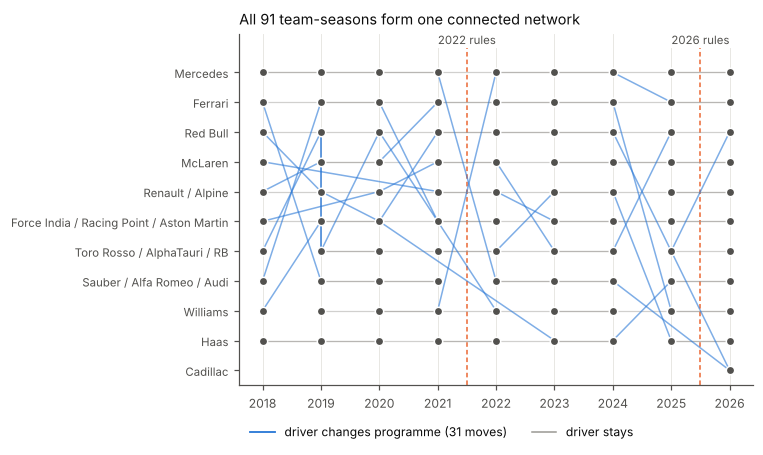

In [29]:
# Figure 1 -- the mobility network, laid out by season.
# Rows are car programmes (renamed teams share a row). Each line follows one
# driver from one team-season to the next team-season he raced in. Blue lines
# cross between programmes: these moves identify driver skill and tie the
# seasons onto one scale. Grey lines are drivers staying with a programme.
FIG_LINEAGE = {
    'Toro Rosso': 'Toro Rosso / AlphaTauri / RB', 'AlphaTauri': 'Toro Rosso / AlphaTauri / RB',
    'RB': 'Toro Rosso / AlphaTauri / RB', 'Racing Bulls': 'Toro Rosso / AlphaTauri / RB',
    'Force India': 'Force India / Racing Point / Aston Martin',
    'Racing Point': 'Force India / Racing Point / Aston Martin',
    'Aston Martin': 'Force India / Racing Point / Aston Martin',
    'Renault': 'Renault / Alpine', 'Alpine': 'Renault / Alpine',
    'Sauber': 'Sauber / Alfa Romeo / Audi', 'Alfa Romeo Racing': 'Sauber / Alfa Romeo / Audi',
    'Alfa Romeo': 'Sauber / Alfa Romeo / Audi', 'Kick Sauber': 'Sauber / Alfa Romeo / Audi',
    'Audi': 'Sauber / Alfa Romeo / Audi',
    'Red Bull Racing': 'Red Bull', 'Haas F1 Team': 'Haas',
}
prog = lambda t: FIG_LINEAGE.get(t, t)
rows_order = ['Mercedes', 'Ferrari', 'Red Bull', 'McLaren',
              'Renault / Alpine', 'Force India / Racing Point / Aston Martin',
              'Toro Rosso / AlphaTauri / RB', 'Sauber / Alfa Romeo / Audi',
              'Williams', 'Haas', 'Cadillac']
present = sorted({prog(t) for t in model_df['Team']})
rows_order = [r for r in rows_order if r in present] + [r for r in present if r not in rows_order]
ypos = {r: i for i, r in enumerate(rows_order)}

nodes = model_df[['Season', 'Team']].drop_duplicates()
edges = []
for drv, g in model_df.groupby('Driver'):
    path = sorted(set(zip(g['Season'], g['Team'])))
    for (s1, t1), (s2, t2) in zip(path[:-1], path[1:]):
        edges.append((s1, t1, s2, t2, drv))

fig, ax = plt.subplots(figsize=(7.0, 4.2))
n_cross = 0
for s1, t1, s2, t2, drv in edges:
    cross = prog(t1) != prog(t2)
    n_cross += cross
    ax.plot([s1, s2], [ypos[prog(t1)], ypos[prog(t2)]],
            color=BLUE if cross else GREY, lw=1.0 if cross else 0.8,
            alpha=0.6 if cross else 0.45, zorder=2 if cross else 1)
for r in nodes.itertuples(index=False):
    ax.scatter(r.Season, ypos[prog(r.Team)], s=30, color=INK2, edgecolor='white',
               linewidth=1.0, zorder=3)
ax.set_yticks(range(len(rows_order)))
ax.set_yticklabels(rows_order, fontsize=7.5)
ax.set_xticks(ALL_SEASONS)
ax.grid(axis='y', visible=False)
ax.set_ylim(len(rows_order) - 0.5, -1.3)
for s in (2022, 2026):
    ax.axvline(s - 0.5, color=ORANGE, lw=1.0, ls=(0, (3, 2)), zorder=0)
    ax.text(s - 0.5, -0.95, f'{s} rules', color=INK2, ha='center', fontsize=7.5,
            bbox=dict(facecolor='white', edgecolor='none', pad=1))
ax.legend(handles=[Line2D([], [], color=BLUE, lw=1.2, label=f'driver changes programme ({n_cross} moves)'),
                   Line2D([], [], color=GREY, lw=1.0, label='driver stays')],
          loc='upper left', bbox_to_anchor=(0, -0.08), ncol=2, frameon=False)
ax.set_title(f'All {len(nodes)} team-seasons form one connected network',
             loc='left')
fig.tight_layout()
save(fig, 'fig1_mobility_network')
plt.show()

saved figures/fig2_track_evolution.pdf and .png


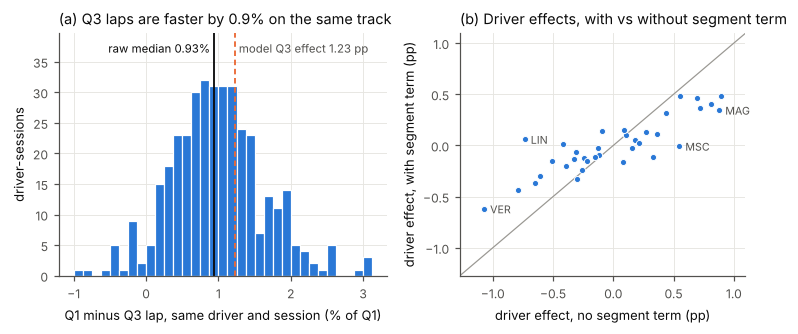

374 driver-sessions with both Q1 and Q3 times; median 0.935%, model Q3 effect 1.232 pp
largest shifts (without minus with):
      with  without  shift
LIN  0.061   -0.736 -0.797
MSC -0.006    0.547  0.553
MAG  0.346    0.878  0.532
VER -0.618   -1.073 -0.455
ANT -0.115    0.328  0.443
BEA  0.015   -0.415 -0.430


In [30]:
# Figure 2 -- track evolution and why the segment term is needed.
# (a) raw evidence: for drivers who set both a Q1 and a Q3 time in the same
#     session, how much faster the Q3 lap was. (b) driver effects estimated with
#     and without the segment term.
seg = segment_times.merge(best[['CircuitID', 'Season', 'Driver']],
                          on=['CircuitID', 'Season', 'Driver'])
seg = seg.dropna(subset=['Q1', 'Q3'])
seg['Evo'] = 100 * (seg['Q1'] - seg['Q3']) / seg['Q1']
per_session = seg.groupby(['CircuitID', 'Season'])['Evo'].median()
raw_median = float(seg['Evo'].median())
model_q3 = -segment_effect.get('Q3', np.nan)

res_noseg = estimate(best, segments=False)
both = pd.DataFrame({'with': pd.Series(driver_effect),
                     'without': pd.Series(res_noseg['driver_effect'])}).dropna()
both['shift'] = both['without'] - both['with']

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.0, 3.1),
                             gridspec_kw={'width_ratios': [1.15, 1]})
a1.hist(seg['Evo'], bins=np.arange(-1.0, 3.25, 0.125), color=BLUE,
        edgecolor='white', linewidth=0.8)
a1.axvline(raw_median, color=INK, lw=1.2)
a1.axvline(model_q3, color=ORANGE, lw=1.2, ls=(0, (3, 2)))
ytop = a1.get_ylim()[1]
a1.set_ylim(0, ytop * 1.18)
a1.text(raw_median - 0.05, ytop * 1.14, f'raw median {raw_median:.2f}%',
        va='top', ha='right', fontsize=7.5)
a1.text(model_q3 + 0.05, ytop * 1.14, f'model Q3 effect {model_q3:.2f} pp',
        va='top', ha='left', fontsize=7.5, color=INK2)
a1.set_xlabel('Q1 minus Q3 lap, same driver and session (% of Q1)')
a1.set_ylabel('driver-sessions')
a1.set_title(f'(a) Q3 laps are faster by {raw_median:.1f}% on the same track',
             loc='left')

lim = [min(both.min()) - 0.2, max(both[['with', 'without']].max()) + 0.2]
a2.plot(lim, lim, color=GREY, lw=0.8, zorder=1)
a2.scatter(both['without'], both['with'], s=16, color=BLUE, edgecolor='white',
           linewidth=0.6, zorder=3)
for d, r in both.reindex(both['shift'].abs().sort_values(ascending=False).index).head(4).iterrows():
    a2.annotate(d, (r['without'], r['with']), xytext=(4, -3), textcoords='offset points',
                fontsize=7, color=INK2)
a2.set_xlim(lim); a2.set_ylim(lim)
a2.set_xlabel('driver effect, no segment term (pp)')
a2.set_ylabel('driver effect, with segment term (pp)')
a2.set_title('(b) Driver effects, with vs without segment term', loc='left')
fig.tight_layout()
save(fig, 'fig2_track_evolution')
plt.show()
print(f"{len(seg)} driver-sessions with both Q1 and Q3 times; "
      f"median {raw_median:.3f}%, model Q3 effect {model_q3:.3f} pp")
print("largest shifts (without minus with):")
print(both.sort_values('shift', key=abs, ascending=False).head(6).round(3).to_string())

saved figures/fig3_car_effects_dumbbell.pdf and .png


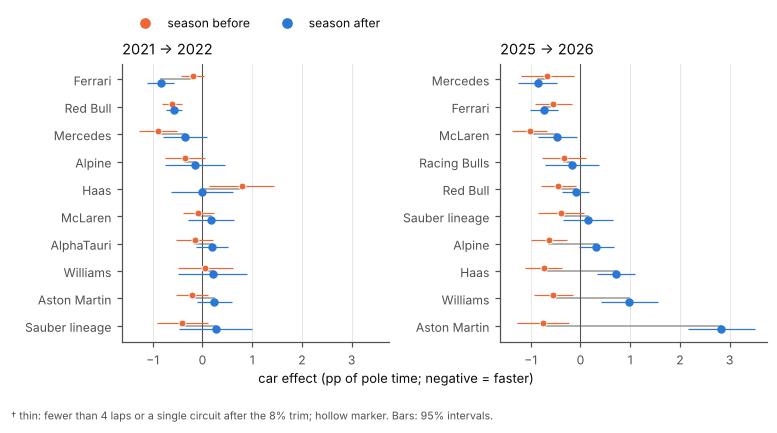

In [31]:
# Figure 3 -- car effects either side of each regulation change (dumbbell).
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.8), sharex=True)
for ax, (name, (pre, post)) in zip(axes, SHOCKS.items()):
    d = delta_frames[name].sort_values('Post').reset_index(drop=True)
    yy = np.arange(len(d))
    for i, r in d.iterrows():
        se_pre, se_post = res['car_se'][r.PreUnit], res['car_se'][r.PostUnit]
        ax.plot([r.Pre, r.Post], [i, i], color=GREY, lw=1.0, zorder=1)
        ax.errorbar(r.Pre, i - 0.12, xerr=1.96 * se_pre, fmt='o', ms=4.5,
                    color=ORANGE, mfc=ORANGE, mec='white', mew=0.6,
                    elinewidth=0.8, capsize=0, zorder=3)
        thin_post = r.PostUnit in thin_units
        ax.errorbar(r.Post, i + 0.12, xerr=1.96 * se_post, fmt='o', ms=4.5,
                    color=BLUE, mfc='white' if thin_post else BLUE, mec=BLUE,
                    mew=1.0, elinewidth=0.8, capsize=0, zorder=4)
    labels = [SHORT.get(t, t) + (' †' if (r.PreUnit in thin_units or r.PostUnit in thin_units) else '')
              for t, r in zip(d['Team'], d.itertuples())]
    ax.set_yticks(yy); ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.axvline(0, color=INK2, lw=0.7)
    ax.grid(axis='y', visible=False)
    ax.set_title(f'{pre} → {post}', loc='left')
fig.supxlabel('car effect (pp of pole time; negative = faster)', fontsize=8.5, y=0.06)
axes[0].legend(handles=[
    Line2D([], [], marker='o', ls='', color=ORANGE, label='season before'),
    Line2D([], [], marker='o', ls='', color=BLUE, label='season after')],
    loc='lower left', bbox_to_anchor=(0, 1.08), ncol=2, frameon=False)
fig.text(0.0, -0.02, '† thin: fewer than 4 laps or a single circuit after the 8% trim; '
         'hollow marker. Bars: 95% intervals.', fontsize=7, color=INK2)
fig.tight_layout()
save(fig, 'fig3_car_effects_dumbbell')
plt.show()

saved figures/fig4_regulation_deltas.pdf and .png


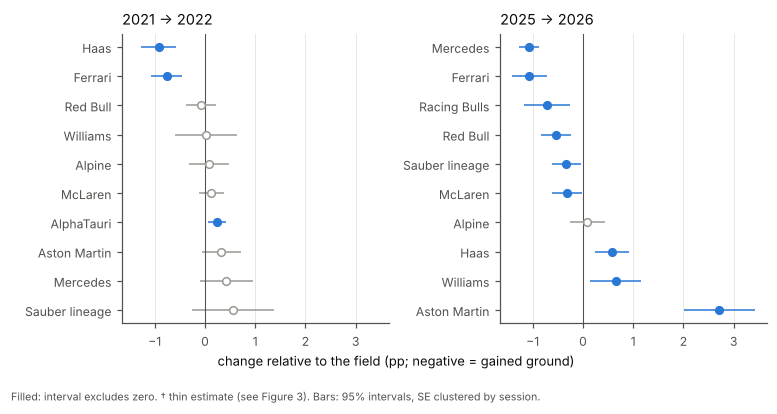

In [32]:
# Figure 4 -- relative change at each regulation change, with 95% intervals.
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.6), sharex=True)
for ax, (name, (pre, post)) in zip(axes, SHOCKS.items()):
    d = delta_frames[name].sort_values('RelDelta').reset_index(drop=True)
    for i, r in d.iterrows():
        thin_ = r.PreUnit in thin_units or r.PostUnit in thin_units
        sig = abs(r.RelDelta) > 1.96 * r.SE
        col = BLUE if sig else GREY
        ax.errorbar(r.RelDelta, i, xerr=1.96 * r.SE, fmt='o', ms=5,
                    color=col, mfc='white' if (thin_ or not sig) else col,
                    mec=col, mew=1.0, elinewidth=1.0, capsize=0)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([SHORT.get(t, t) + (' †' if (r.PreUnit in thin_units or r.PostUnit in thin_units) else '')
                        for t, r in zip(d['Team'], d.itertuples())])
    ax.invert_yaxis()
    ax.axvline(0, color=INK2, lw=0.7)
    ax.grid(axis='y', visible=False)
    ax.set_title(f'{pre} → {post}', loc='left')
fig.supxlabel('change relative to the field (pp; negative = gained ground)',
              fontsize=8.5, y=0.06)
fig.text(0.0, -0.02, 'Filled: interval excludes zero. † thin estimate (see Figure 3). '
         'Bars: 95% intervals, SE clustered by session.', fontsize=7, color=INK2)
fig.tight_layout()
save(fig, 'fig4_regulation_deltas')
plt.show()

saved figures/fig5_driver_effects.pdf and .png


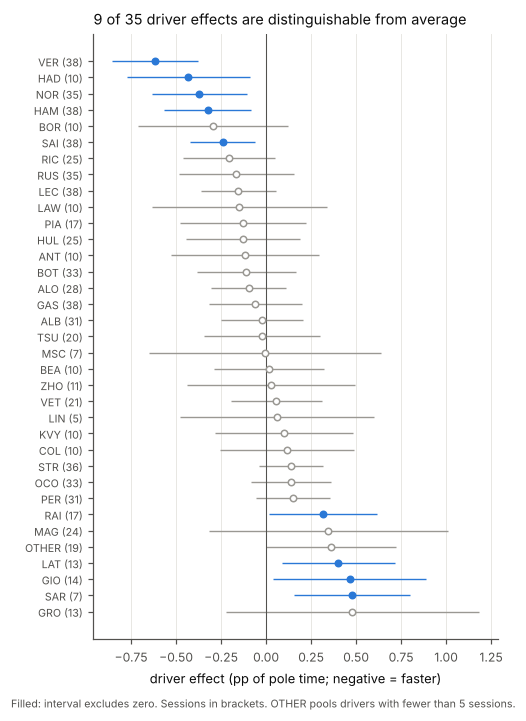

In [33]:
# Figure 5 -- every driver effect with its 95% interval.
NAMES = {}
if 'FullName' in best.columns:
    NAMES = best.drop_duplicates('Driver').set_index('Driver')['FullName'].to_dict()
d = drv_tbl.sort_values('Effect').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(4.6, 6.4))
for i, r in d.iterrows():
    sig = r.Sig == '*'
    col = BLUE if sig else GREY
    ax.errorbar(r.Effect, i, xerr=1.96 * r.SE, fmt='o', ms=4.2, color=col,
                mfc=col if sig else 'white', mec=col, mew=1.0,
                elinewidth=0.9, capsize=0)
ax.set_yticks(range(len(d)))
ax.set_yticklabels([f"{x} ({int(n)})" for x, n in zip(d['Driver'], d['Sessions'])],
                   fontsize=7)
ax.invert_yaxis()
ax.axvline(0, color=INK2, lw=0.7)
ax.grid(axis='y', visible=False)
ax.set_xlabel('driver effect (pp of pole time; negative = faster)')
nsig = int((d.Sig == '*').sum())
ax.set_title(f'{nsig} of {len(d)} driver effects are distinguishable from average',
             loc='left')
fig.text(0.0, -0.01, 'Filled: interval excludes zero. Sessions in brackets. '
         'OTHER pools drivers with fewer than 5 sessions.', fontsize=7, color=INK2)
fig.tight_layout()
save(fig, 'fig5_driver_effects')
plt.show()

saved figures/fig6_teammate_validation.pdf and .png


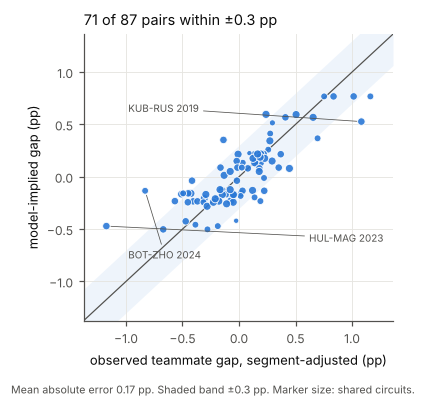

In [34]:
# Figure 6 -- in-sample validation: model-implied vs observed teammate gaps.
fig, ax = plt.subplots(figsize=(3.6, 3.5))
lim = [min(tm['adj_obs'].min(), tm['model'].min()) - 0.2,
       max(tm['adj_obs'].max(), tm['model'].max()) + 0.2]
ax.fill_between(lim, [l - 0.3 for l in lim], [l + 0.3 for l in lim],
                color=BLUE, alpha=0.08, lw=0, zorder=0)
ax.plot(lim, lim, color=INK2, lw=0.8, zorder=1)
ax.scatter(tm['adj_obs'], tm['model'], s=8 + 4 * tm['n'], color=BLUE,
           edgecolor='white', linewidth=0.6, alpha=0.9, zorder=3)
# The three largest errors, labelled in empty corners with leader lines.
spots = [(0.62, -0.62, 'left'), (-0.98, -0.78, 'left'), (-0.98, 0.62, 'left')]
for (tx, ty, ha), (_, r) in zip(spots, tm.sort_values('err_adj', ascending=False).head(3).iterrows()):
    ax.annotate(f"{r.A}-{r.B} {r.Season}", (r.adj_obs, r.model), xytext=(tx, ty),
                textcoords='data', fontsize=6.5, color=INK2, ha=ha,
                arrowprops=dict(arrowstyle='-', color=INK2, lw=0.5,
                                shrinkA=1, shrinkB=3))
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('observed teammate gap, segment-adjusted (pp)')
ax.set_ylabel('model-implied gap (pp)')
within = int((tm['err_adj'] <= 0.3).sum())
ax.set_title(f'{within} of {len(tm)} pairs within ±0.3 pp', loc='left')
fig.text(0.0, -0.03, f"Mean absolute error {tm['err_adj'].mean():.2f} pp. "
         "Shaded band ±0.3 pp. Marker size: shared circuits.", fontsize=7, color=INK2)
fig.tight_layout()
save(fig, 'fig6_teammate_validation')
plt.show()

saved figures/fig7_robustness.pdf and .png


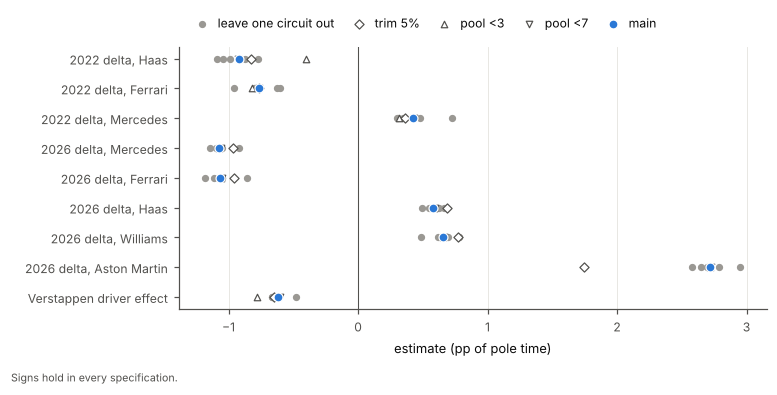

In [35]:
# Figure 7 -- headline estimates across every robustness specification.
rows = list(main_head.keys())
fig, ax = plt.subplots(figsize=(7.0, 3.4))
yy = np.arange(len(rows))
for i, k in enumerate(rows):
    vals = loco_tbl.loc[k].dropna().values
    ax.scatter(vals, np.full(len(vals), i), s=14, color=GREY, zorder=2,
               label='leave one circuit out' if i == 0 else None)
    for col, mk in (('trim 5%', 'D'), ('pool <3', '^'), ('pool <7', 'v')):
        ax.scatter(spec_tbl.loc[k, col], i, s=18, marker=mk, facecolor='white',
                   edgecolor=INK2, linewidth=0.8, zorder=3,
                   label=col if i == 0 else None)
    ax.scatter(main_head[k], i, s=34, color=BLUE, edgecolor='white', linewidth=0.8,
               zorder=4, label='main' if i == 0 else None)
ax.set_yticks(yy); ax.set_yticklabels(rows)
ax.invert_yaxis()
ax.axvline(0, color=INK2, lw=0.7)
ax.grid(axis='y', visible=False)
ax.set_xlabel('estimate (pp of pole time)')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.02), ncol=5, frameon=False,
          handletextpad=0.3, columnspacing=1.0)
missing = [f"{k} without {c}" for c in CIRCUIT_GROUPS for k in rows
           if np.isnan(loco_tbl.loc[k, f'drop {c}'])]
allv = pd.concat([loco_tbl, spec_tbl], axis=1)
flips = [k for k in rows
         if (np.sign(allv.loc[k].dropna()) != np.sign(main_head[k])).any()]
note = ('Signs hold in every specification.' if not flips
        else 'Sign changes in some specification: ' + ', '.join(flips) + '.')
if missing:
    note += ' Not estimable: ' + '; '.join(missing) + '.'
fig.text(0.0, -0.03, note, fontsize=7, color=INK2)
fig.tight_layout()
save(fig, 'fig7_robustness')
plt.show()

## Section 9 — Outputs

All seven figures are in `figures/` as PDF and PNG. The tables printed in
Sections 6 and 7 are the numbers the paper reports.

In [36]:
for f in sorted(os.listdir(FIG_DIR)):
    print(f)

fig1_mobility_network.pdf
fig1_mobility_network.png
fig2_track_evolution.pdf
fig2_track_evolution.png
fig3_car_effects_dumbbell.pdf
fig3_car_effects_dumbbell.png
fig4_regulation_deltas.pdf
fig4_regulation_deltas.png
fig5_driver_effects.pdf
fig5_driver_effects.png
fig6_teammate_validation.pdf
fig6_teammate_validation.png
fig7_robustness.pdf
fig7_robustness.png
